# Issue #12: Fine-tuning SmolLM2-135M on arXiv abstracts (Complex corpus)

This notebook follows the Hugging Face [causal language modeling guide](https://huggingface.co/docs/transformers/en/tasks/language_modeling), with the team's changes:

* **Model:** `HuggingFaceTB/SmolLM2-135M` (the base model, not Instruct), not GPT-2
* **Data:** a small sample of our arXiv abstracts (`complex_data.txt`) instead of the guide's ELI5 dataset
* **Block size:** 256 tokens
* **Training:** a few hundred steps with `logging_steps=10`

**What "causal language modeling" means:** the model reads text left to right and learns to guess the next token. Fine-tuning just means we keep training an already-trained model on *our* text, so it starts to sound more like our corpus.

**How to use:** run the cells top to bottom. Put `complex_data.txt` in `backend/notebooks/corpora/complex/` (or change `CORPUS_PATH` in the settings cell). A GPU (for example Colab: *Runtime → Change runtime type → T4 GPU*) makes training take minutes instead of much longer, but it also works on CPU.

## 1. Install libraries
Skip this cell if they are already installed on your machine.

In [1]:
!pip install -q "transformers>=4.46" datasets accelerate matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Settings
Everything you might want to change lives here, so your partner can see the whole setup in one place.

* `SEED` fixes the randomness so the same settings give the same results.
* `PROMPTS` are the prefixes we use **before and after** training. Pick two that look like the start of something from your corpus.
* `GEN_KWARGS` are the generation settings. We use the exact same ones before and after, otherwise the comparison isn't fair.

In [2]:
import os, math, random

MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"

# Path is relative to this notebook (backend/notebooks/complex/)
CORPUS_PATH = "../corpora/complex/complex_data.txt"
SAMPLE_SIZE = 2000        # how many abstracts to use, out of ~6,800 ("a small sample")

SEED = 42
BLOCK_SIZE = 256          # team setting (the guide uses 128)
MAX_STEPS = 300           # "a few hundred steps is plenty"
LOGGING_STEPS = 10        # team setting, gives enough points for the loss graph
BATCH_SIZE = 8
LEARNING_RATE = 5e-5

OUTPUT_DIR = "checkpoints/smollm2-finetuned"   # the saved model goes here (git-ignored, never commit it)

# Two academic prefixes (issue #12). Over a third of the abstracts start with "We".
PROMPTS = [
    "In this paper, we",
    "We present a new method for",
]

GEN_KWARGS = dict(
    max_new_tokens=60,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
)

## 3. Fix the seed and pick a device
`set_seed` seeds Python, NumPy and PyTorch together. We call it again right before every generation so each one starts from the same random state.

In [3]:
import torch
from transformers import set_seed

set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

C:\Users\aegis\ACC-recursive-model-collapse\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## 4. Load the base model and tokenizer
This is the snippet from the team guide. The **tokenizer** turns text into numbers (token ids) and back. The **model** predicts the next token.

SmolLM2 has no padding token, so we reuse the end-of-text token for padding, as the guide does for GPT-2.

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model.to(device)
print(f"Parameters: {model.num_parameters() / 1e6:.0f}M")

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2197.14it/s]

Parameters: 135M


## 5. "Before" examples
We generate from the untouched base model first, so we have something to compare against later.
The helper resets the seed every time, which is what makes "same prefix + same seed = same output" true.

In [5]:
def generate(m, prompt, seed=SEED):
    m.eval()
    set_seed(seed)
    inputs = tokenizer(prompt, return_tensors="pt").to(m.device)
    with torch.no_grad():
        out = m.generate(**inputs, **GEN_KWARGS, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True)

before = {}
for p in PROMPTS:
    before[p] = generate(model, p)
    print(f"--- {p!r}\n{before[p]}\n")

--- 'In this paper, we'
In this paper, we present an experimental study of the role of the EMRC in the regulation of the transcription factor c-Myc by the transcriptional activator c-Myc in response to the EMRC activation.

The role of the EMRC in the regulation of the transcription factor c-

--- 'We present a new method for'
We present a new method for solving the linear system of equations with a new set of constraints, known as the Jacobian method. In this method, the Jacobian matrix of the system is constructed using the Jacobian method, with the constraint matrix used to form the Jacobian of the system.

## How to use the



## 6. Load a small sample of the arXiv abstracts
Instead of the guide's ELI5 dataset, we load our own text file.

In `complex_data.txt` each abstract is a **paragraph**: it is wrapped over several lines, and abstracts are separated by blank lines. So we load with `sample_by="paragraph"` to get one example per abstract (the default would give one example per *line*, cutting abstracts into pieces).
Then we join the wrapped lines back into one line, shuffle with our seed, keep `SAMPLE_SIZE` abstracts, and hold out 10% as a test set so we can check the model on text it didn't train on.

In [6]:
import re
from datasets import load_dataset

if not os.path.exists(CORPUS_PATH):
    raise FileNotFoundError(f"Put complex_data.txt at {CORPUS_PATH!r} or change CORPUS_PATH in the settings cell")

raw = load_dataset("text", data_files=CORPUS_PATH, sample_by="paragraph", split="train")
raw = raw.map(lambda x: {"text": re.sub(r"\s+", " ", x["text"]).strip()})   # undo the line wrapping
raw = raw.filter(lambda x: len(x["text"]) > 0)
print("Abstracts in the full file:", len(raw))

raw = raw.shuffle(seed=SEED).select(range(min(SAMPLE_SIZE, len(raw))))
splits = raw.train_test_split(test_size=0.1, seed=SEED)
print(splits)
print("Example:", splits["train"][0]["text"][:400])

Abstracts in the full file: 6780
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 1800
    })
    test: Dataset({
        features: ['text'],
        num_rows: 200
    })
})
Example: The absolute frequencies of the hyperfine components of the R(26) 62-0 transition in molecular iodine at 501.7 nm are measured for the first time with an optical clockwork based on a femtosecond laser frequency comb generator. The set-up is composed of an Ar+ laser locked to a hyperfine component of the R(26) 62-0 transition detected in a continuously pumped low-pressure cell (0.33 Pa). The detect


### 6b. Inspect the sample for LaTeX and formatting issues
Issue #12 asks us to look for LaTeX or other formatting left in the text. This counts how many abstracts in our sample contain each pattern and shows one example of each, so you can write them up in the PR.

In [7]:
checks = {
    "inline LaTeX math $...$": r"\$[^$]+\$",
    "LaTeX commands (\\cite, \\alpha, ...)": r"\\[a-zA-Z]+",
    "curly braces { }": r"[{}]",
    "caret for powers (10^3)": r"\^",
    "tilde for 'about' (~3)": r"~",
    "URLs": r"https?://",
    "non-ASCII characters": r"[^\x00-\x7f]",
}
for name, pattern in checks.items():
    hits = [t for t in raw["text"] if re.search(pattern, t)]
    print(f"{name:32} {len(hits):5} of {len(raw)} abstracts")
    if hits:
        m = re.search(pattern, hits[0])
        print("    e.g. ...", hits[0][max(0, m.start() - 40): m.end() + 40], "...")

inline LaTeX math $...$              0 of 2000 abstracts
LaTeX commands (\cite, \alpha, ...)     0 of 2000 abstracts
curly braces { }                     0 of 2000 abstracts
caret for powers (10^3)            122 of 2000 abstracts
    e.g. ...  level of 7.5+-2.2_(stat)+-2.3_(syst)*10^-12 cm^-2 s^-1 corresponding to a 9% Cra ...
tilde for 'about' (~3)             102 of 2000 abstracts
    e.g. ...  evidence of intrinsic UV absorption is ~50%, which is slightly lower than Crensh ...
URLs                                 3 of 2000 abstracts
    e.g. ... ness estimates, is available on-line at http://www.2slaq.info/ ...
non-ASCII characters                 0 of 2000 abstracts


## 7. Tokenize and cut into blocks of 256
Same two steps as the guide:

1. **Tokenize** every example into token ids.
2. **Group texts:** glue all the token ids together into one long stream, then chop it into chunks of exactly `BLOCK_SIZE` (256). The leftover at the end that doesn't fill a full block is dropped.

Each block becomes one training example. The labels are just a copy of the inputs; the model shifts them by one internally to learn "predict the next token".

In [8]:
def tokenize(batch):
    return tokenizer(batch["text"])

tokenized = splits.map(tokenize, batched=True, remove_columns=splits["train"].column_names)

def group_texts(examples):
    concatenated = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated[list(examples.keys())[0]])
    total_length = (total_length // BLOCK_SIZE) * BLOCK_SIZE
    result = {
        k: [t[i : i + BLOCK_SIZE] for i in range(0, total_length, BLOCK_SIZE)]
        for k, t in concatenated.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_dataset = tokenized.map(group_texts, batched=True)
print(lm_dataset)
if len(lm_dataset["train"]) == 0:
    raise ValueError("Not enough text to make a single 256-token block. Increase SAMPLE_SIZE or add more text.")

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1080
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 128
    })
})


## 8. Train
The `DataCollatorForLanguageModeling` with `mlm=False` batches the blocks for next-token prediction (mlm=True would be BERT-style masking, which we don't want).

Notes on the settings:
* `max_steps` stops training after a fixed number of steps no matter how big the dataset is.
* `logging_steps=10` records the training loss every 10 steps, which is what we plot.
* `seed` makes the shuffling and dropout repeatable.
* We save the model ourselves in step 10, so `save_strategy="no"` avoids filling the disk with intermediate checkpoints.

In [9]:
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

training_args = TrainingArguments(
    output_dir="checkpoints/trainer-tmp",
    max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    logging_steps=LOGGING_STEPS,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="no",
    seed=SEED,
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=lm_dataset["train"],
    eval_dataset=lm_dataset["test"],
    data_collator=data_collator,
)

trainer.train()

C:\Users\aegis\ACC-recursive-model-collapse\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss,Validation Loss
50,3.391891,3.388952
100,3.445283,3.374358
150,3.367646,3.366868
200,3.307357,3.364447
250,3.362030,3.363420
300,3.310765,3.363053


TrainOutput(global_step=300, training_loss=3.3810839462280273, metrics={'train_runtime': 920.383, 'train_samples_per_second': 2.608, 'train_steps_per_second': 0.326, 'total_flos': 391508420198400.0, 'train_loss': 3.3810839462280273, 'epoch': 2.2222222222222223})

## 9. Training-loss graph (screenshot this for the checklist)
**Loss** measures how surprised the model is by the next token. Lower is better. We want the blue line to go down.
If the orange eval loss starts going *up* while training loss keeps dropping, the model is memorising the training text (overfitting); fewer steps would be better.

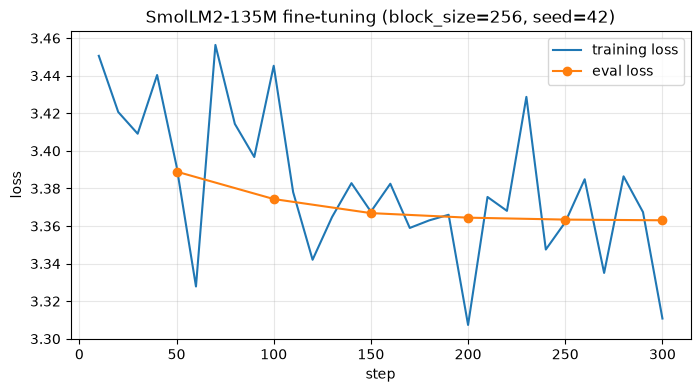

C:\Users\aegis\ACC-recursive-model-collapse\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
3.310765,3.363053,300


Perplexity on held-out text: 28.88


In [10]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history
train = [(l["step"], l["loss"]) for l in logs if "loss" in l]
evals = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train), label="training loss")
if evals:
    plt.plot(*zip(*evals), "o-", label="eval loss")
plt.xlabel("step"); plt.ylabel("loss")
plt.title(f"SmolLM2-135M fine-tuning (block_size={BLOCK_SIZE}, seed={SEED})")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

eval_results = trainer.evaluate()
print(f"Perplexity on held-out text: {math.exp(eval_results['eval_loss']):.2f}")

## 10. Save the checkpoint
This writes the fine-tuned weights and tokenizer to `OUTPUT_DIR`. The folder is a few hundred MB, which is why it is in `.gitignore` and must **not** be committed.

In [11]:
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  8.68it/s]

['config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 11. Reload the checkpoint and check it works
We load the model back from disk as a completely new object, generate with the same prefix and seed, and compare it to the model still in memory. If saving worked, the two outputs are identical.

In [12]:
reloaded = AutoModelForCausalLM.from_pretrained(OUTPUT_DIR).to(device)

prompt = PROMPTS[0]
from_memory = generate(trainer.model, prompt)
from_disk = generate(reloaded, prompt)
print("In-memory model:\n", from_memory, "\n")
print("Reloaded model:\n", from_disk, "\n")
print("Same output:", from_memory == from_disk)

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3453.92it/s]


In-memory model:
 In this paper, we present an improved solution for the time-evolution of the magnetic field in the case of a non-linear magnetic field, i.e., of a non-uniform magnetic field. The key problem is to find an effective solution to the non-linear equation of motion for the magnetic field and to compute 

Reloaded model:
 In this paper, we present an improved solution for the time-evolution of the magnetic field in the case of a non-linear magnetic field, i.e., of a non-uniform magnetic field. The key problem is to find an effective solution to the non-linear equation of motion for the magnetic field and to compute 

Same output: True


## 12. "After" examples, side by side with "before"
Same prefixes, same seed, same `GEN_KWARGS` as step 5, so the only thing that changed is the training.
The results are also saved to `before_after.md` so you can paste them into your PR.

In [13]:
lines = [f"Settings: seed={SEED}, block_size={BLOCK_SIZE}, max_steps={MAX_STEPS}, {GEN_KWARGS}\n"]
for p in PROMPTS:
    after = generate(reloaded, p)
    print(f"=== Prefix: {p!r}\n--- BEFORE\n{before[p]}\n--- AFTER\n{after}\n")
    lines += [f"### Prefix: `{p}`", "**Before:**", "", before[p], "", "**After:**", "", after, ""]

with open("before_after.md", "w") as f:
    f.write("\n".join(lines))

=== Prefix: 'In this paper, we'
--- BEFORE
In this paper, we present an experimental study of the role of the EMRC in the regulation of the transcription factor c-Myc by the transcriptional activator c-Myc in response to the EMRC activation.

The role of the EMRC in the regulation of the transcription factor c-
--- AFTER
In this paper, we present an improved solution for the time-evolution of the magnetic field in the case of a non-linear magnetic field, i.e., of a non-uniform magnetic field. The key problem is to find an effective solution to the non-linear equation of motion for the magnetic field and to compute

=== Prefix: 'We present a new method for'
--- BEFORE
We present a new method for solving the linear system of equations with a new set of constraints, known as the Jacobian method. In this method, the Jacobian matrix of the system is constructed using the Jacobian method, with the constraint matrix used to form the Jacobian of the system.

## How to use the
--- AFTER
We pres

## Checklist
- [ ] Notebook runs on my partner's setup
- [ ] Text issues noted from step 6b (what LaTeX/formatting is left in the sample)
- [ ] Training-loss screenshot (`training_loss.png` from step 9)
- [ ] Checkpoint saved and reloaded, `Same output: True` in step 11
- [ ] Two before/after examples with the same prefixes, seed and settings (`before_after.md`)
- [ ] Work is on my issue branch, opened as a PR, with no model files committed